# Figura 6: descritores lagrangianos

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU-USUARIO/pendulo-caotico/blob/main/06_descritores_lagrangianos.ipynb)

Notebook de apoio ao artigo *Caracterização do caos no pêndulo forçado e amortecido: instabilidade, informação e geometria do espaço de fase*, **Seção VI, Figura 6**.

Os diagnósticos dos notebooks anteriores resumem uma trajetória em um número ou em um conjunto assintótico. Os descritores lagrangianos (LDs) olham para o **espaço de condições iniciais em tempo finito**: cada ponto $(\theta_0, \omega_0)$ de uma malha recebe o comprimento de arco, no espaço de fases, da trajetória que parte dele. Mudanças bruscas desse campo revelam as estruturas que separam comportamentos dinâmicos distintos.

O cálculo é feito para o regime periódico ($f = 0{,}9$) e para o caótico ($f = 1{,}2$), cada um com dois horizontes de integração.

**Tempo de execução:** cerca de 20 segundos.

## O descritor

Para a condição inicial $x_0 = (\theta_0, \omega_0)$, no instante $t_0$ e com horizonte $\tau$, Eq. (14):

$$L^+(x_0; t_0, \tau) = \int_{t_0}^{t_0+\tau}\sqrt{\dot\theta^{2} + \dot\omega^{2}}\;dt .$$

Como o sistema é forçado, $t_0$ fixa a fase do forçamento e tem de ser o mesmo em toda a malha; aqui $t_0 = 0$. Onde duas condições iniciais vizinhas seguem caminhos diferentes, $L^+$ muda bruscamente, e essas mudanças aparecem como cristas em $\lVert\nabla L^+\rVert$. Com integração para frente no tempo ($L^+$), as cristas acompanham as variedades estáveis das trajetórias hiperbólicas; as variedades instáveis apareceriam na versão para trás, $L^-$.

## Código

### 1. Bibliotecas e parâmetros

Mesmos $q$ (`beta`), $\Omega$ e $T_d$ dos outros notebooks. A malha cobre $\theta_0 \in [-\pi, \pi]$ e $\omega_0 \in [-0{,}6;\ 2{,}5]$.

In [1]:
# Dependências: numpy, matplotlib e numba.
# No Colab o Numba normalmente já vem instalado; se faltar, descomente a linha abaixo.
# !pip install numba

import math
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.colors import LogNorm   # escala logarítmica para o gradiente
from numba import njit, prange

# =====================================================================
# PARÂMETROS FÍSICOS E DO SISTEMA
# =====================================================================
beta = 0.5                  # q: amortecimento
Omega = 2 / 3               # frequência do forçamento
T_D = 2 * math.pi / Omega   # período do forçamento
F_PER, F_CAO = 0.9, 1.2     # regimes periódico e caótico

TH_LIM = (-math.pi, math.pi)   # domínio em theta
W_LIM = (-0.6, 2.5)            # domínio em omega

FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

### 2. Integração em toda a malha

`derivs` devolve $\dot\theta$, $\dot\omega$ e a velocidade $\sqrt{\dot\theta^2 + \dot\omega^2}$.

Em `calcular_grid_ld`, a velocidade é tratada como uma terceira variável e integrada com os mesmos pesos do RK4 que o estado. Assim $L^+$ tem a mesma precisão da trajetória, sem precisar de uma regra de quadratura à parte.

Cada condição inicial é independente das outras. Por isso o laço externo usa `prange` com `@njit(parallel=True)`: o Numba distribui as linhas da malha entre os núcleos do processador.

In [2]:
@njit
def derivs(t, th, om, q, f, Om):
    dth = om
    dom = -q * om - math.sin(th) + f * math.cos(Om * t)
    speed = math.sqrt(dth * dth + dom * dom)
    return dth, dom, speed


@njit(parallel=True)
def calcular_grid_ld(theta_vals, omega_vals, tau, dt, q, f, Om):
    N_om = len(omega_vals)
    N_th = len(theta_vals)
    ld_map = np.zeros((N_om, N_th))
    steps = int(tau / dt)

    for i in prange(N_om):                  # linhas em paralelo
        om0 = omega_vals[i]
        for j in range(N_th):
            th = theta_vals[j]
            om = om0
            t = 0.0                         # t0 = 0 para toda a malha
            ld_val = 0.0

            for _ in range(steps):
                k1_th, k1_om, k1_s = derivs(t, th, om, q, f, Om)

                t_mid = t + 0.5 * dt
                k2_th, k2_om, k2_s = derivs(
                    t_mid, th + 0.5 * dt * k1_th, om + 0.5 * dt * k1_om, q, f, Om
                )
                k3_th, k3_om, k3_s = derivs(
                    t_mid, th + 0.5 * dt * k2_th, om + 0.5 * dt * k2_om, q, f, Om
                )

                t_end = t + dt
                k4_th, k4_om, k4_s = derivs(
                    t_end, th + dt * k3_th, om + dt * k3_om, q, f, Om
                )

                th += (dt / 6.0) * (k1_th + 2 * k2_th + 2 * k3_th + k4_th)
                om += (dt / 6.0) * (k1_om + 2 * k2_om + 2 * k3_om + k4_om)
                ld_val += (dt / 6.0) * (k1_s + 2 * k2_s + 2 * k3_s + k4_s)   # L+
                t += dt

            ld_map[i, j] = ld_val

    return ld_map

### 3. Campo $L^+$ e norma do gradiente

`gerar_ld_e_gradiente` monta a malha de $N \times N$ condições iniciais, calcula $L^+$ com 100 passos por período ($\Delta t = T_d/100$) e obtém o gradiente com `np.gradient`, que usa diferenças centradas e os espaçamentos reais em $\omega_0$ e $\theta_0$. Devolve a malha, $L^+$ e $\lVert\nabla L^+\rVert$.

In [3]:
def gerar_ld_e_gradiente(f_val, tau_periodos, N=300, spp=100):
    tau = tau_periodos * T_D
    dt = T_D / spp

    theta_vals = np.linspace(TH_LIM[0], TH_LIM[1], N)
    omega_vals = np.linspace(W_LIM[0], W_LIM[1], N)

    # descritor lagrangiano L+
    ld_map = calcular_grid_ld(
        theta_vals, omega_vals, tau, dt, beta, f_val, Omega
    )

    # gradiente numérico ||∇L+|| (eixo 0 = omega, eixo 1 = theta)
    dL_dom, dL_dth = np.gradient(ld_map, omega_vals, theta_vals)
    grad_norm = np.sqrt(dL_dth**2 + dL_dom**2)

    return theta_vals, omega_vals, ld_map, grad_norm

### 4. Figura de um regime

`figura_ld` calcula $L^+$ e $\lVert\nabla L^+\rVert$ para $\tau = 3T_d$ e $\tau = 10T_d$ e monta uma figura de $2 \times 2$ painéis. O gradiente usa escala logarítmica (`LogNorm`) com limites nos percentis 5 e 99,5, para que as cristas finas não sejam apagadas pelos poucos picos muito altos.

A Figura 6 do artigo mostra a linha $\tau = 3T_d$ de cada regime. A linha $\tau = 10T_d$ é o teste de robustez proposto na Seção VI: repetir o cálculo para pelo menos dois horizontes.

In [4]:
def figura_ld(f_val, nome_regime, arquivo, N_grid=300):
    th_v, om_v, ld_3T, grad_3T = gerar_ld_e_gradiente(f_val, tau_periodos=3, N=N_grid)
    th_v, om_v, ld_10T, grad_10T = gerar_ld_e_gradiente(f_val, tau_periodos=10, N=N_grid)

    fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))

    # colormaps e normalizações
    cmap_ld = 'plasma'      # mapa escalar L+
    cmap_grad = 'inferno'   # fundo escuro: as cristas do gradiente "brilham"

    # limites por percentil para evitar que picos extremos apaguem linhas finas
    vmax_g3T = np.percentile(grad_3T, 99.5)
    vmin_g3T = max(np.percentile(grad_3T, 5), 1e-3)
    vmax_g10T = np.percentile(grad_10T, 99.5)
    vmin_g10T = max(np.percentile(grad_10T, 5), 1e-3)

    # (a) L+, tau = 3T
    pcm00 = axes[0, 0].pcolormesh(th_v, om_v, ld_3T, shading='auto', cmap=cmap_ld)
    fig.colorbar(pcm00, ax=axes[0, 0], label=r'$L^+$')
    axes[0, 0].set_title(r'(a) $L^+(\theta_0, \omega_0)$, $\tau = 3T$', fontsize=10)

    # (b) ||∇L+||, tau = 3T
    pcm01 = axes[0, 1].pcolormesh(th_v, om_v, grad_3T, shading='auto', cmap=cmap_grad,
                                  norm=LogNorm(vmin=vmin_g3T, vmax=vmax_g3T))
    fig.colorbar(pcm01, ax=axes[0, 1], label=r'$\|\nabla L^+\|$')
    axes[0, 1].set_title(r'(b) $\|\nabla L^+(\theta_0, \omega_0)\|$, $\tau = 3T$', fontsize=10)

    # (c) L+, tau = 10T
    pcm10 = axes[1, 0].pcolormesh(th_v, om_v, ld_10T, shading='auto', cmap=cmap_ld)
    fig.colorbar(pcm10, ax=axes[1, 0], label=r'$L^+$')
    axes[1, 0].set_title(r'(c) $L^+(\theta_0, \omega_0)$, $\tau = 10T$', fontsize=10)

    # (d) ||∇L+||, tau = 10T
    pcm11 = axes[1, 1].pcolormesh(th_v, om_v, grad_10T, shading='auto', cmap=cmap_grad,
                                  norm=LogNorm(vmin=vmin_g10T, vmax=vmax_g10T))
    fig.colorbar(pcm11, ax=axes[1, 1], label=r'$\|\nabla L^+\|$')
    axes[1, 1].set_title(r'(d) $\|\nabla L^+(\theta_0, \omega_0)\|$, $\tau = 10T$', fontsize=10)

    # eixos
    for ax in axes.flat:
        ax.set_xlim(*TH_LIM)
        ax.set_ylim(*W_LIM)
        ax.set_xlabel(r'$\theta_0$ (rad)')
        ax.set_ylabel(r'$\omega_0$ (rad/s)')
        ax.set_xticks(
            [-math.pi, -math.pi / 2, 0, math.pi / 2, math.pi],
            [r'$-\pi$', r'$-\pi/2$', '0', r'$\pi/2$', r'$\pi$'],
        )

    fig.suptitle(f'Descritores Lagrangianos e Gradientes no Regime {nome_regime} ($f = {f_val}$)',
                 fontsize=12, y=0.98)
    plt.tight_layout()
    plt.savefig(FIG_DIR / arquivo, dpi=300)
    plt.show()
    return ld_3T, grad_3T, ld_10T, grad_10T

### 5. Regime periódico, $f = 0{,}9$

Calculando Descritores Lagrangianos para f = 0.9 (Periódico)...


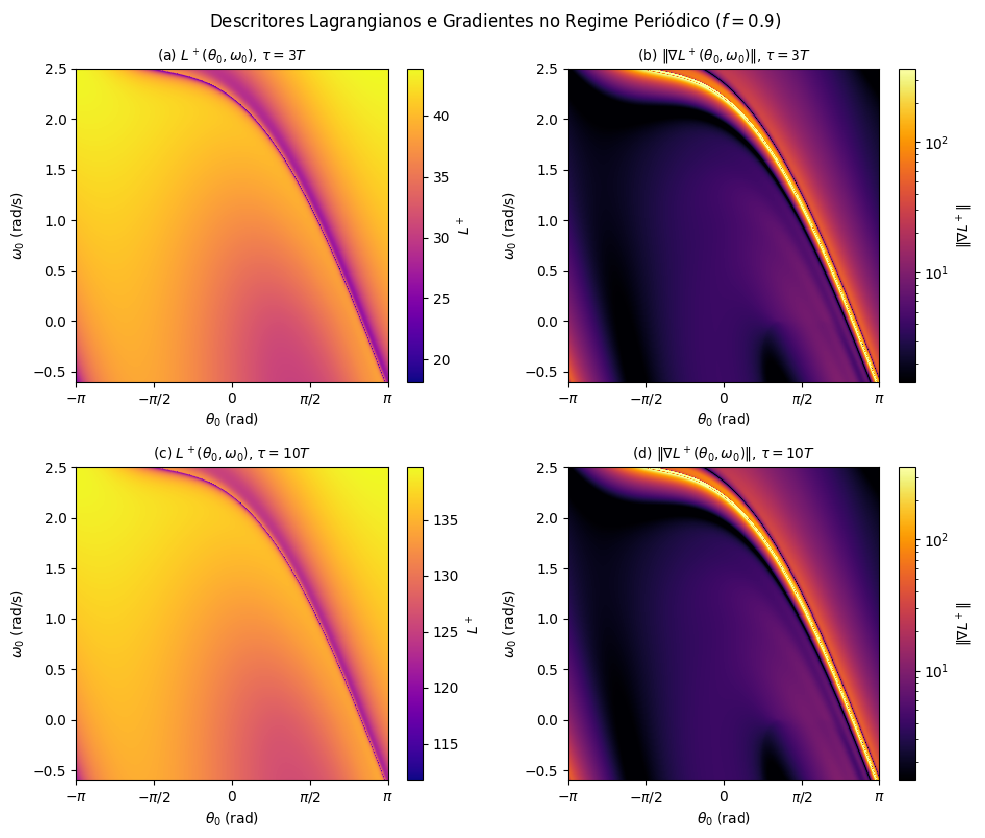

In [5]:
print("Calculando Descritores Lagrangianos para f = 0.9 (Periódico)...")
res_per = figura_ld(F_PER, 'Periódico', 'figura6_descritores_periodico.png')

### 6. Regime caótico, $f = 1{,}2$

Calculando Descritores Lagrangianos para f = 1.2 (Caótico)...


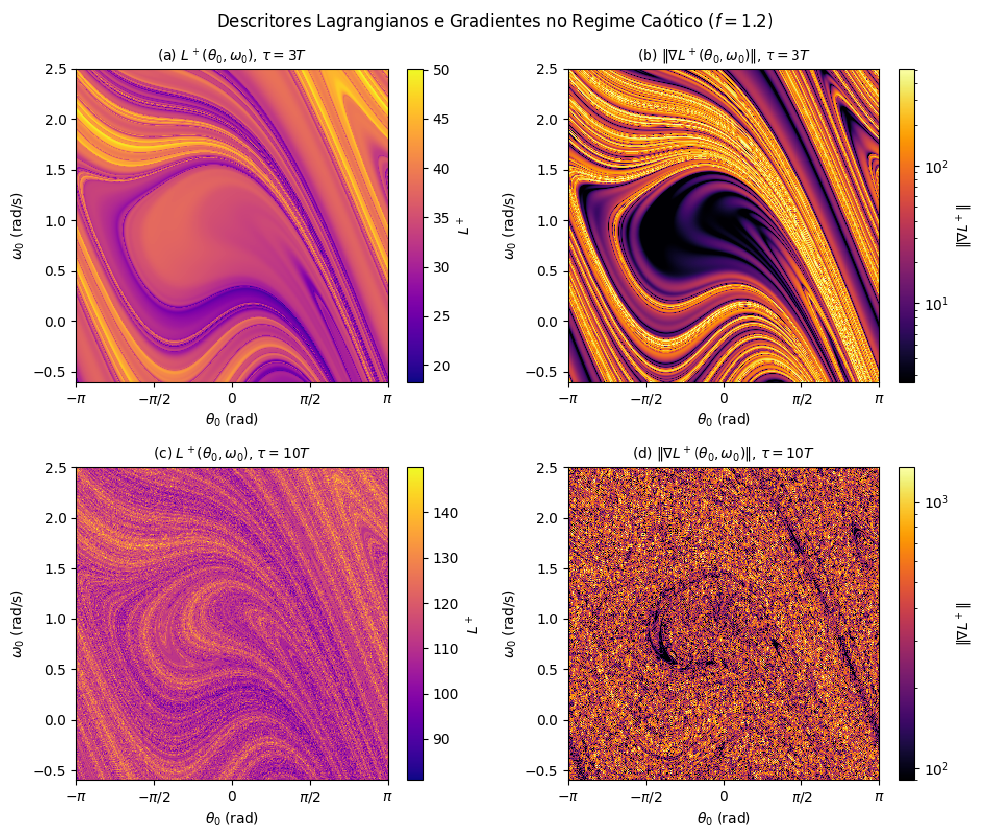

In [6]:
print("Calculando Descritores Lagrangianos para f = 1.2 (Caótico)...")
res_cao = figura_ld(F_CAO, 'Caótico', 'figura6_descritores_caotico.png')

### 7. Comparação quantitativa entre os horizontes

Duas grandezas simples resumem a diferença entre os regimes: a amplitude de $L^+$ na malha (máximo menos mínimo) e a mediana de $\lVert\nabla L^+\rVert$, comparadas entre $\tau = 3T_d$ e $\tau = 10T_d$. Imprime-se também o espaçamento da malha, que limita o tamanho das estruturas que podem ser resolvidas.

In [7]:
N_grid = 300
dth0 = (TH_LIM[1] - TH_LIM[0])/(N_grid - 1)
dom0 = (W_LIM[1] - W_LIM[0])/(N_grid - 1)
print(f"espaçamento da malha: Δθ0 = {dth0:.4f} rad, Δω0 = {dom0:.4f}\n")

for nome, (ld3, g3, ld10, g10) in (("periódico f=0,9", res_per), ("caótico   f=1,2", res_cao)):
    print(f"{nome}: amplitude de L+ = {np.ptp(ld3):5.1f} (3T), {np.ptp(ld10):5.1f} (10T) | "
          f"mediana de |grad L+| = {np.median(g3):6.1f} (3T), {np.median(g10):6.1f} (10T), "
          f"razão {np.median(g10)/np.median(g3):.1f}")

espaçamento da malha: Δθ0 = 0.0210 rad, Δω0 = 0.0104

periódico f=0,9: amplitude de L+ =  25.7 (3T),  27.9 (10T) | mediana de |grad L+| =    3.9 (3T),    3.9 (10T), razão 1.0
caótico   f=1,2: amplitude de L+ =  31.8 (3T),  69.1 (10T) | mediana de |grad L+| =   40.9 (3T),  370.7 (10T), razão 9.1


## Leitura dos resultados

**Regime periódico.** $L^+$ varia suavemente e $\lVert\nabla L^+\rVert$ destaca uma única crista lisa, que separa duas regiões de condições iniciais cujas trajetórias percorrem caminhos diferentes antes de chegar ao mesmo atrator. A figura é praticamente a mesma para $\tau = 3T_d$ e $10T_d$: depois do transiente, todas as trajetórias estão no mesmo ciclo e $L^+$ só ganha uma parcela igual em toda a malha. Por isso a mediana do gradiente é a mesma nos dois horizontes (3,9) e a amplitude de $L^+$ quase não muda (25,7 para 27,9).

**Regime caótico.** Já em $\tau = 3T_d$ o gradiente forma uma rede densa de cristas finas, dobradas umas sobre as outras, em torno de uma região central mais lisa. De $3T_d$ para $10T_d$ a amplitude de $L^+$ dobra (31,8 para 69,1) e a mediana do gradiente cresce cerca de 9 vezes (40,9 para 370,7): condições iniciais vizinhas continuam se separando, e as diferenças de $L^+$ entre elas crescem com o horizonte. Em $\tau = 10T_d$ o espaçamento entre as cristas fica menor que o da malha ($\Delta\theta_0 \approx 0{,}021$ rad, $\Delta\omega_0 \approx 0{,}010$) e o painel (d) parece ruído: a estrutura existe, mas a malha de $300 \times 300$ não a resolve. Esse é o sentido prático da ressalva do artigo de que o LD depende de $\tau$ e da resolução, e é por isso que a Figura 6 usa $\tau = 3T_d$.

## Para explorar

- Use `N_grid=100` em `figura_ld` para testes rápidos; as estruturas principais já aparecem.
- Troque o horizonte para $\tau = 1T_d$ e $\tau = 20T_d$ e acompanhe como as cristas se multiplicam no regime caótico.
- Mude o instante inicial $t_0$ (em `calcular_grid_ld`, `t = 0.0`) para $T_d/2$: a figura muda, porque a fase do forçamento faz parte da condição inicial.